In [1]:
# Imports
import qiskit
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

print("Qiskit Version:", qiskit.__version__)
simulator = AerSimulator()

def superdense_coding(message="00", bit_flip_error=False, shots=1024):
    if message not in {"00", "01", "10", "11"}:
        raise ValueError("Message must be 00, 01, 10, or 11")

    qc = QuantumCircuit(2, 2)
    qc.h(0)
    qc.cx(0, 1)  # shared |Phi+> Bell pair
    qc.barrier()

    if message[0] == "1":
        qc.z(0)
    if message[1] == "1":
        qc.x(0)
    qc.barrier()

    if bit_flip_error:
        qc.x(0)

    qc.cx(0, 1)
    qc.h(0)
    qc.measure([0, 1], [0, 1])

    counts = simulator.run(qc, shots=shots).result().get_counts()
    return qc, counts


def decoded_counts(counts):
    # Convert Qiskit displayed c1c0 keys to message order.
    return {key[::-1]: value for key, value in counts.items()}


def decoded_message(counts):
    return max(decoded_counts(counts), key=decoded_counts(counts).get)


Qiskit Version: 2.5.1


Circuit for message 00
     ┌───┐      ░  ░      ┌───┐┌─┐
q_0: ┤ H ├──■───░──░───■──┤ H ├┤M├
     └───┘┌─┴─┐ ░  ░ ┌─┴─┐└┬─┬┘└╥┘
q_1: ─────┤ X ├─░──░─┤ X ├─┤M├──╫─
          └───┘ ░  ░ └───┘ └╥┘  ║ 
c: 2/═══════════════════════╩═══╩═
                            1   0 
Raw measurement counts: {'00': 1024}
Decoded message: 00
Correct decoding: True


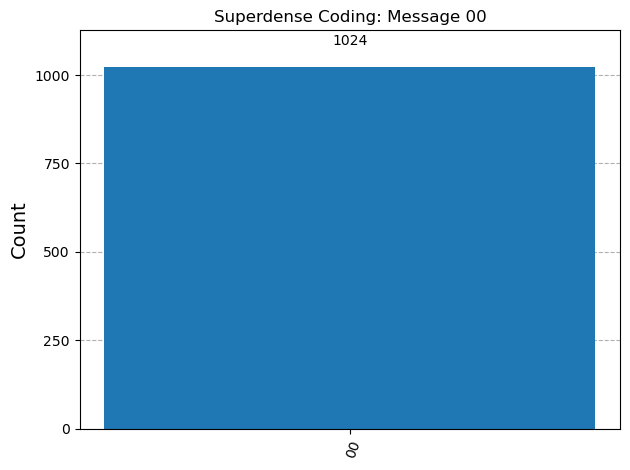

In [2]:
message = "00"
qc, counts = superdense_coding(message, shots=1024)
print("Circuit for message", message)
print(qc)
print("Raw measurement counts:", counts)
print("Decoded message:", decoded_message(counts))
print("Correct decoding:", decoded_message(counts) == message)
plot_histogram(counts, title="Superdense Coding: Message 00")
